# Variational Autoencoder (VAE) for Face Generation — Completed Lab

**Dataset:** LFW (`/kaggle/input/datasets/jessicali9530/lfw-dataset`)  
**Runtime:** Kaggle GPU (T4 / T4 × 2)  
**Goal:** Implement a dense VAE, train it, reconstruct faces, generate samples, and compare β = 0 with β = 1.

This notebook is organized to complete the assignment end-to-end. It uses a deterministic subset for a practical Kaggle runtime; the subset size and epoch counts can be increased after the first successful run.

## 1. Setup and configuration

The model is a fully connected VAE, matching the assignment architecture. `DataParallel` is enabled automatically when more than one CUDA GPU is visible. The notebook uses one GPU if only one is available.

In [17]:
import os
import random
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True
torch.set_num_threads(4)

DATASET_ROOT = Path("/kaggle/input/datasets/jessicali9530/lfw-dataset")

IMAGE_SIZE = 45
CHANNELS = 3
INPUT_DIM = CHANNELS * IMAGE_SIZE * IMAGE_SIZE
LATENT_DIM = 100

# Runtime-conscious settings for Kaggle T4.
MAX_IMAGES = 6000       # Set to None to use every eligible image.
BATCH_SIZE = 128
EPOCHS = 4              # Main VAE training
BETA_EXPERIMENT_EPOCHS = 2
LEARNING_RATE = 1e-3
BETA = 1.0
NUM_WORKERS = 4

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0
print("Device:", DEVICE)
print("Visible GPUs:", N_GPUS)
if N_GPUS:
    for i in range(N_GPUS):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))

Device: cuda
Visible GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 2. Load the LFW dataset

The scan is performed once using `os.walk`. The original lab's balancing rule (remove identities with 25 or more images) is retained. If the dataset's structure contains an extra nested folder, recursive scanning still finds the JPG files.

In [18]:
if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_ROOT}. "
        "In Kaggle, use Add Input and attach jessicali9530/lfw-dataset."
    )

print("Scanning dataset once...")
image_paths = []
for root, dirs, files in os.walk(DATASET_ROOT):
    for filename in files:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(Path(root) / filename)

if not image_paths:
    raise FileNotFoundError(f"No face images found below {DATASET_ROOT}")

counts = Counter(p.parent.name for p in image_paths)
eligible_paths = [p for p in image_paths if counts[p.parent.name] < 25]
eligible_paths.sort()

if MAX_IMAGES is not None:
    eligible_paths = eligible_paths[:MAX_IMAGES]

image_df = pd.DataFrame({
    "path": eligible_paths,
    "person": [p.parent.name for p in eligible_paths],
})

print(f"Dataset root: {DATASET_ROOT}")
print(f"Images discovered: {len(image_paths):,}")
print(f"Images after identity balancing / subset: {len(image_df):,}")
print(f"Identities represented: {image_df['person'].nunique():,}")
display(image_df.head())

Scanning dataset once...
Dataset root: /kaggle/input/datasets/jessicali9530/lfw-dataset
Images discovered: 13,233
Images after identity balancing / subset: 6,000
Identities represented: 3,242


,path,person
0,/kaggle/input/datasets/jessicali9530/lfw-datas...,AJ_Cook
1,/kaggle/input/datasets/jessicali9530/lfw-datas...,AJ_Lamas
2,/kaggle/input/datasets/jessicali9530/lfw-datas...,Aaron_Eckhart
3,/kaggle/input/datasets/jessicali9530/lfw-datas...,Aaron_Guiel
4,/kaggle/input/datasets/jessicali9530/lfw-datas...,Aaron_Patterson


## 3. Dataset, train/validation split, and image preview

Images are center-cropped, resized to 45 × 45, and converted to tensors in [0, 1], as required by the sigmoid decoder and binary cross-entropy reconstruction term.

Train images: 4800
Validation images: 1200
Batch shape: (128, 3, 45, 45)


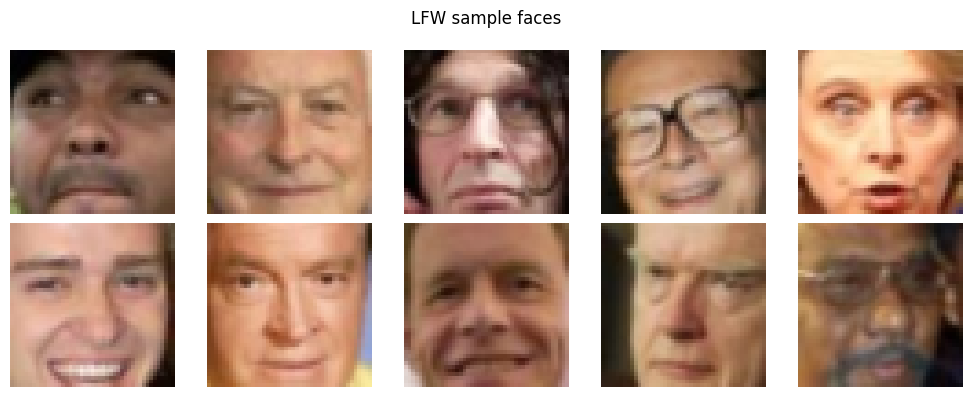

In [19]:
class FaceDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = list(paths)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        with Image.open(path) as im:
            im = im.convert("RGB")
            w, h = im.size
            mx = min(80, max(0, (w - 1) // 3))
            my = min(80, max(0, (h - 1) // 3))
            im = im.crop((mx, my, w - mx, h - my))
            return self.transform(im)

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

train_paths, val_paths = train_test_split(
    image_df["path"].tolist(),
    test_size=0.2,
    random_state=SEED,
)

train_dataset = FaceDataset(train_paths, transform)
val_dataset = FaceDataset(val_paths, transform)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
    "persistent_workers": NUM_WORKERS > 0,
}
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)

sample_batch = next(iter(train_loader))
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Batch shape:", tuple(sample_batch.shape))
assert sample_batch.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert sample_batch.min() >= 0 and sample_batch.max() <= 1

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, img in zip(axes.flat, sample_batch[:10]):
    ax.imshow(img.permute(1, 2, 0))
    ax.axis("off")
plt.suptitle("LFW sample faces")
plt.tight_layout()
plt.show()

## 4. VAE architecture: encoder, latent distribution, and decoder

The encoder produces two vectors:
- `mu`: mean of the approximate posterior
- `logvar`: log variance of the approximate posterior

The reparameterization trick samples `z = mu + exp(0.5 × logvar) × epsilon`, where epsilon is standard Gaussian noise. This keeps the sampling operation differentiable with respect to the encoder parameters.

In [20]:
class DenseFaceVAE(nn.Module):
    def __init__(self, input_dim=INPUT_DIM, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1500),
            nn.ReLU(),
            nn.Linear(1500, 1000),
            nn.ReLU(),
        )
        self.mu_head = nn.Linear(1000, latent_dim)
        self.logvar_head = nn.Linear(1000, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 1000),
            nn.ReLU(),
            nn.Linear(1000, 1500),
            nn.ReLU(),
            nn.Linear(1500, input_dim),
            nn.Sigmoid(),
        )

    def encode(self, x):
        features = self.encoder(x.flatten(start_dim=1))
        return self.mu_head(features), self.logvar_head(features)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + std * epsilon

    def decode(self, z):
        pixels = self.decoder(z)
        return pixels.view(-1, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar


base_model = DenseFaceVAE()
model = nn.DataParallel(base_model) if N_GPUS > 1 else base_model
model = model.to(DEVICE)

test_batch = sample_batch[:4].to(DEVICE)
recon, mu, logvar = model(test_batch)
print("Reconstruction:", tuple(recon.shape))
print("mu:", tuple(mu.shape), "| logvar:", tuple(logvar.shape))
assert recon.shape == test_batch.shape
assert mu.shape == logvar.shape == (4, LATENT_DIM)
assert recon.min() >= 0 and recon.max() <= 1

# Verify gradients reach both posterior heads.
(recon.mean() + mu.mean() + logvar.mean()).backward()
core = model.module if isinstance(model, nn.DataParallel) else model
assert core.mu_head.weight.grad is not None
assert core.logvar_head.weight.grad is not None
model.zero_grad(set_to_none=True)
print("VAE architecture and gradient checks passed.")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/linear.py:134: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return F.linear(input, self.weight, self.bias)


Reconstruction: (4, 3, 45, 45)
mu: (4, 100) | logvar: (4, 100)
VAE architecture and gradient checks passed.


## 5. Negative ELBO loss

The objective is reconstruction BCE plus β times the KL divergence to a unit Gaussian prior:

\[
L = BCE(\hat{x},x) + \beta D_{KL}(q(z|x)\|N(0,I))
\]

Both terms use `reduction="sum"` and are normalized by batch size, so values are reported per image.

In [21]:
def vae_loss(reconstruction, target, mu, logvar, beta=1.0):
    batch_size = target.size(0)

    reconstruction_loss = F.binary_cross_entropy(
        reconstruction, target, reduction="sum"
    ) / batch_size

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    ) / batch_size

    total_loss = reconstruction_loss + beta * kl_loss
    return total_loss, reconstruction_loss.detach(), kl_loss.detach()


dummy_mu = torch.zeros(2, LATENT_DIM, device=DEVICE)
dummy_logvar = torch.zeros_like(dummy_mu)
dummy_x = torch.full((2, 3, IMAGE_SIZE, IMAGE_SIZE), 0.5, device=DEVICE)
_, _, dummy_kl = vae_loss(dummy_x, dummy_x, dummy_mu, dummy_logvar)
assert torch.isclose(dummy_kl, torch.tensor(0.0, device=DEVICE))
print("Loss sanity check passed; KL(q=N(0,I) || p=N(0,I)) = 0.")

Loss sanity check passed; KL(q=N(0,I) || p=N(0,I)) = 0.


## 6. Training and validation functions

The training loop uses a single visible GPU or `DataParallel` across both visible GPUs. A short main run is configured by default to make the notebook finish reliably in a Kaggle session. The experiment below uses the same data and architecture with two β values.

In [22]:
def unwrap(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def train_step(model, batch, optimizer, beta):
    model.train()
    batch = batch.to(DEVICE, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)

    reconstruction, mu, logvar = model(batch)
    total, recon_loss, kl_loss = vae_loss(
        reconstruction, batch, mu, logvar, beta
    )
    total.backward()
    optimizer.step()

    return total.item(), recon_loss.item(), kl_loss.item()


@torch.no_grad()
def evaluate(model, loader, beta):
    model.eval()
    totals = np.zeros(3, dtype=np.float64)
    examples = 0

    for batch in loader:
        batch = batch.to(DEVICE, non_blocking=True)
        reconstruction, mu, logvar = model(batch)
        values = vae_loss(reconstruction, batch, mu, logvar, beta)
        n = batch.size(0)
        totals += np.array([v.item() for v in values]) * n
        examples += n

    return totals / max(examples, 1)


def train_model(model, train_loader, val_loader, beta, epochs, label="model"):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {
        "train_total": [], "val_total": [],
        "val_reconstruction": [], "val_kl": [],
    }

    for epoch in range(1, epochs + 1):
        start = time.time()
        running_total = 0.0
        seen = 0

        for batch in train_loader:
            total, _, _ = train_step(model, batch, optimizer, beta)
            running_total += total * batch.size(0)
            seen += batch.size(0)

        val_total, val_recon, val_kl = evaluate(model, val_loader, beta)
        history["train_total"].append(running_total / max(seen, 1))
        history["val_total"].append(val_total)
        history["val_reconstruction"].append(val_recon)
        history["val_kl"].append(val_kl)

        print(
            f"{label} | Epoch {epoch}/{epochs} | "
            f"train={running_total/max(seen,1):.2f} | "
            f"val={val_total:.2f} | BCE={val_recon:.2f} | "
            f"KL={val_kl:.2f} | {time.time()-start:.1f}s"
        )

    return history

## 7. Train the main VAE (β = 1)

Training loss and validation loss are plotted after each epoch. If you have more time, increase `EPOCHS` in the configuration cell.

Main VAE (beta=1) | Epoch 1/4 | train=4019.09 | val=4004.80 | BCE=4001.84 | KL=2.97 | 143.9s
Main VAE (beta=1) | Epoch 2/4 | train=3981.53 | val=3973.98 | BCE=3958.69 | KL=15.29 | 4.4s
Main VAE (beta=1) | Epoch 3/4 | train=3952.70 | val=3941.47 | BCE=3923.86 | KL=17.61 | 4.4s
Main VAE (beta=1) | Epoch 4/4 | train=3939.19 | val=3921.87 | BCE=3904.21 | KL=17.66 | 4.4s


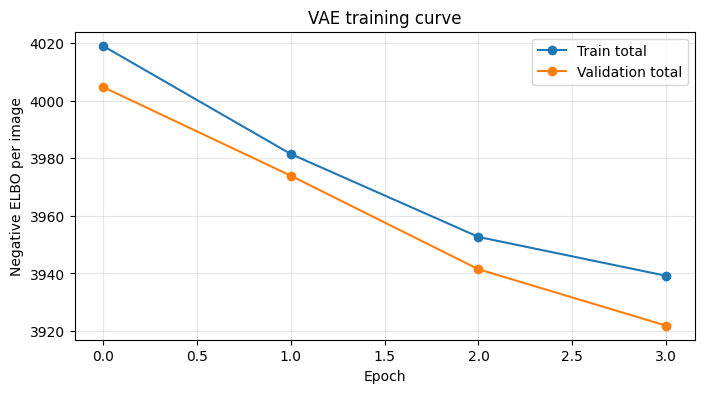

In [23]:
history = train_model(
    model, train_loader, val_loader,
    beta=BETA, epochs=EPOCHS, label="Main VAE (beta=1)"
)

plt.figure(figsize=(8, 4))
plt.plot(history["train_total"], marker="o", label="Train total")
plt.plot(history["val_total"], marker="o", label="Validation total")
plt.xlabel("Epoch")
plt.ylabel("Negative ELBO per image")
plt.title("VAE training curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Reconstruct validation faces

The posterior mean is decoded for stable reconstructions. The top row contains original faces; the bottom row contains reconstructed faces.

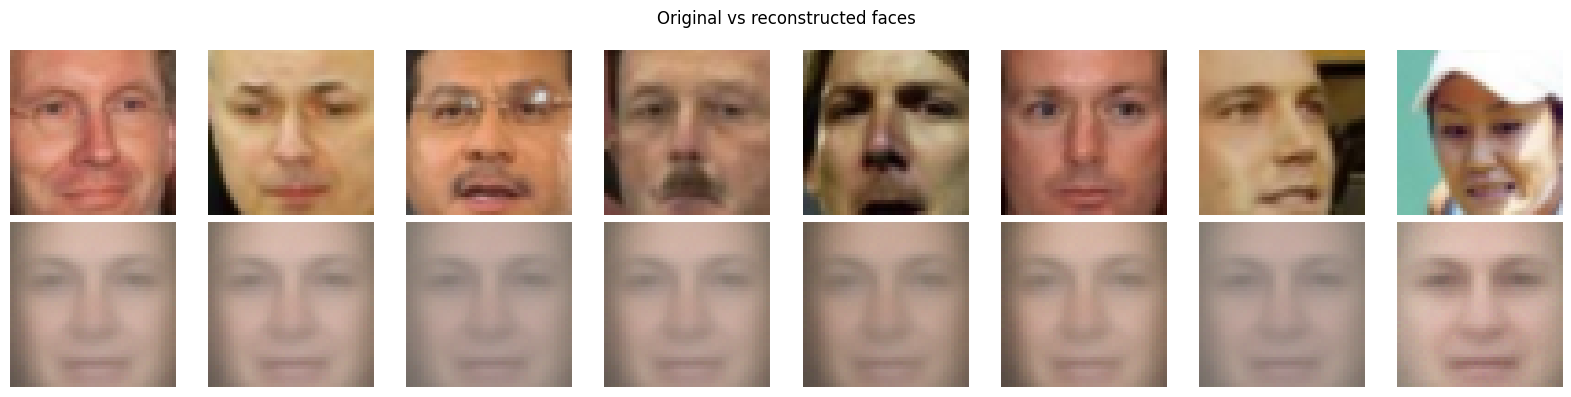

In [24]:
model.eval()
validation_faces = next(iter(val_loader))[:8].to(DEVICE)
with torch.no_grad():
    mu_val, _ = unwrap(model).encode(validation_faces)
    reconstructed_faces = unwrap(model).decode(mu_val)

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(validation_faces[i].cpu().permute(1, 2, 0))
    axes[1, i].imshow(reconstructed_faces[i].cpu().permute(1, 2, 0).clamp(0, 1))
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.suptitle("Original vs reconstructed faces")
plt.tight_layout()
plt.show()

## 9. Generate new faces from the prior

Unlike reconstruction, generation does not use an input face. Ten latent vectors are sampled from the unit Gaussian prior and passed through the decoder.

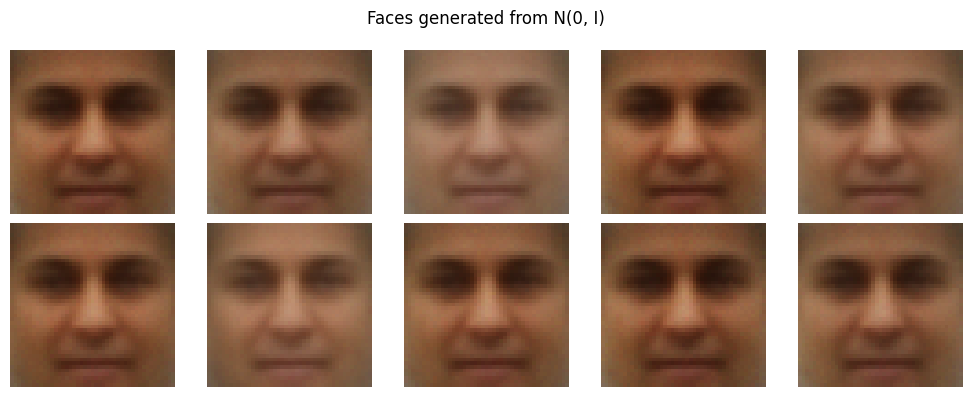

In [25]:
model.eval()
with torch.no_grad():
    z = torch.randn(10, LATENT_DIM, device=DEVICE)
    generated_faces = unwrap(model).decode(z)

assert generated_faces.shape == (10, 3, IMAGE_SIZE, IMAGE_SIZE)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for face, ax in zip(generated_faces.cpu(), axes.flat):
    ax.imshow(face.permute(1, 2, 0).clamp(0, 1))
    ax.axis("off")
plt.suptitle("Faces generated from N(0, I)")
plt.tight_layout()
plt.show()

## 10. β experiment: compare β = 0 and β = 1

Two fresh models are trained for the same number of epochs. At β = 0, the model optimizes reconstruction only. At β = 1, it also regularizes the posterior toward the unit Gaussian prior.

In [26]:
def make_model():
    m = DenseFaceVAE()
    if N_GPUS > 1:
        m = nn.DataParallel(m)
    return m.to(DEVICE)


model_beta_0 = make_model()
history_beta_0 = train_model(
    model_beta_0, train_loader, val_loader,
    beta=0.0, epochs=BETA_EXPERIMENT_EPOCHS, label="Beta experiment (0)"
)

model_beta_1 = make_model()
history_beta_1 = train_model(
    model_beta_1, train_loader, val_loader,
    beta=1.0, epochs=BETA_EXPERIMENT_EPOCHS, label="Beta experiment (1)"
)

beta_results = pd.DataFrame({
    "Beta": [0.0, 1.0],
    "Validation reconstruction (BCE)": [
        history_beta_0["val_reconstruction"][-1],
        history_beta_1["val_reconstruction"][-1],
    ],
    "Validation KL": [
        history_beta_0["val_kl"][-1],
        history_beta_1["val_kl"][-1],
    ],
    "Validation total": [
        history_beta_0["val_total"][-1],
        history_beta_1["val_total"][-1],
    ],
})
display(beta_results)

Beta experiment (0) | Epoch 1/2 | train=4085.95 | val=3968.94 | BCE=3968.94 | KL=37.27 | 4.4s
Beta experiment (0) | Epoch 2/2 | train=3922.50 | val=3900.09 | BCE=3900.09 | KL=84.04 | 4.3s
Beta experiment (1) | Epoch 1/2 | train=4021.50 | val=3993.94 | BCE=3992.95 | KL=0.99 | 4.3s
Beta experiment (1) | Epoch 2/2 | train=3981.26 | val=3972.03 | BCE=3964.72 | KL=7.31 | 4.3s


,Beta,Validation reconstruction (BCE),Validation KL,Validation total
0,0.0,3900.090944,84.035068,3900.090944
1,1.0,3964.720020,7.308280,3972.028343


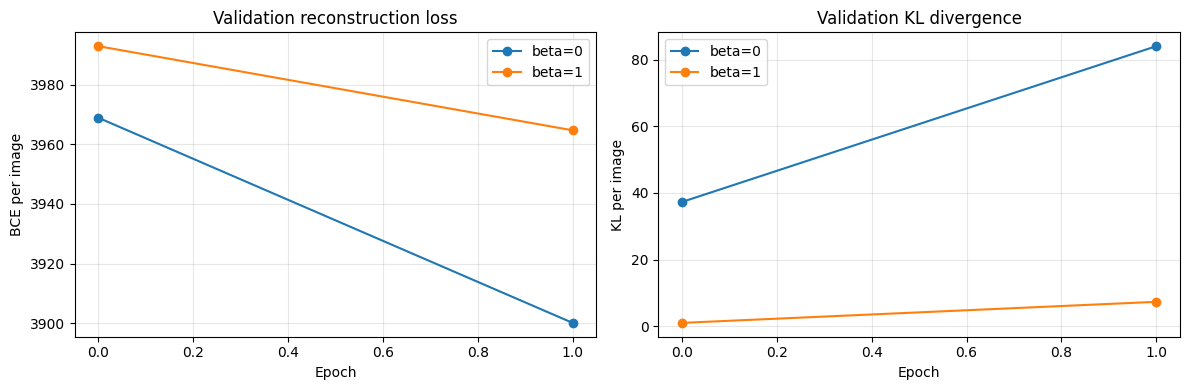

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_beta_0["val_reconstruction"], marker="o", label="beta=0")
axes[0].plot(history_beta_1["val_reconstruction"], marker="o", label="beta=1")
axes[0].set_title("Validation reconstruction loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE per image")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_beta_0["val_kl"], marker="o", label="beta=0")
axes[1].plot(history_beta_1["val_kl"], marker="o", label="beta=1")
axes[1].set_title("Validation KL divergence")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("KL per image")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

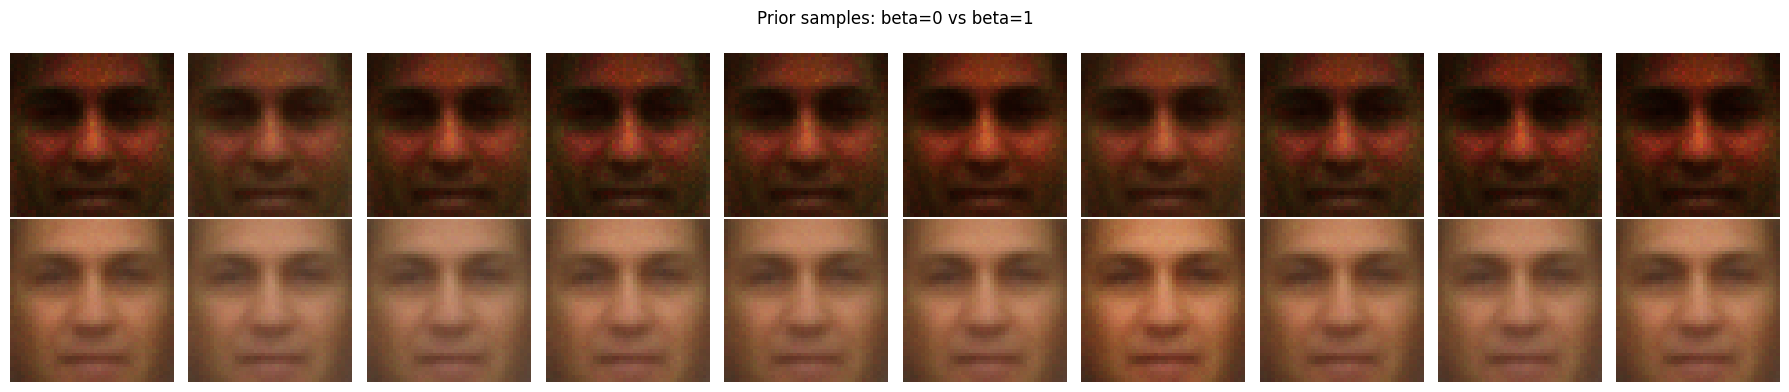

In [28]:
def generate_from_prior(trained_model, n=10):
    trained_model.eval()
    with torch.no_grad():
        z = torch.randn(n, LATENT_DIM, device=DEVICE)
        return unwrap(trained_model).decode(z)

samples_beta_0 = generate_from_prior(model_beta_0)
samples_beta_1 = generate_from_prior(model_beta_1)

fig, axes = plt.subplots(2, 10, figsize=(18, 4))
for i in range(10):
    axes[0, i].imshow(samples_beta_0[i].cpu().permute(1, 2, 0).clamp(0, 1))
    axes[1, i].imshow(samples_beta_1[i].cpu().permute(1, 2, 0).clamp(0, 1))
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("beta=0")
axes[1, 0].set_ylabel("beta=1")
plt.suptitle("Prior samples: beta=0 vs beta=1")
plt.tight_layout()
plt.show()

## 11. Written answers and interpretation

### Encoder and latent variables

1. For a batch of `N` images and `LATENT_DIM = 100`, `mu`, `logvar`, and `z` each have shape `(N, 100)`.
2. The final `mu` and `logvar` layers have no ReLU because both parameters must be able to take arbitrary real values. ReLU would incorrectly constrain them to be non-negative.
3. Direct sampling from a distribution whose parameters depend on the encoder introduces a stochastic sampling operation that does not provide an ordinary differentiable path to the encoder parameters. Reparameterization writes the sample as `z = mu + std * epsilon`, where `epsilon` is independent Gaussian noise, allowing gradients to flow through `mu` and `logvar`.

### β experiment

1. **At β = 0:** the KL term is removed from the objective. The model is optimized only for reconstruction, so there is no explicit pressure for the learned latent distributions to match the unit-normal prior. Consequently, samples drawn from `N(0, I)` may fall in latent regions the decoder has not learned to use.
2. **As β increases:** the KL term receives more weight. This generally encourages a smoother, more regular latent space and can improve prior sampling, but it can reduce reconstruction fidelity because the model has less freedom to encode input-specific details. The actual balance should be interpreted using the measured validation BCE, KL, and generated samples above.
3. **Why no convolution is required:** a VAE is defined by its probabilistic latent-variable model and objective, not by a particular layer type. A dense encoder and decoder can implement it. The disadvantage is that flattening images discards explicit spatial locality, so dense models are less parameter-efficient and often produce blurrier image reconstructions than convolutional VAEs.

### Results note

The numeric values in the β comparison table are produced by executing the experiment cells. Do not invent or manually fill those values before running the notebook.

## 12. Final verification and submission checklist

This cell confirms that the main training history, reconstruction output, and generated samples exist. Save or download the notebook **after running all cells** so the submission contains the plots and measured results.

In [29]:
print("Dataset images used:", len(image_df))
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Device:", DEVICE, "| visible GPUs:", N_GPUS)
print("Main VAE final validation ELBO:", round(history["val_total"][-1], 3))
print("Main VAE final validation BCE:", round(history["val_reconstruction"][-1], 3))
print("Main VAE final validation KL:", round(history["val_kl"][-1], 3))
print("Generated faces:", tuple(generated_faces.shape))
print("\nBeta comparison:")
display(beta_results)

assert len(history["val_total"]) == EPOCHS
assert generated_faces.shape == (10, 3, IMAGE_SIZE, IMAGE_SIZE)
assert len(beta_results) == 2
print("Assignment pipeline completed successfully.")

Dataset images used: 6000
Training images: 4800
Validation images: 1200
Device: cuda | visible GPUs: 2
Main VAE final validation ELBO: 3921.866
Main VAE final validation BCE: 3904.209
Main VAE final validation KL: 17.657
Generated faces: (10, 3, 45, 45)

Beta comparison:


,Beta,Validation reconstruction (BCE),Validation KL,Validation total
0,0.0,3900.090944,84.035068,3900.090944
1,1.0,3964.720020,7.308280,3972.028343


Assignment pipeline completed successfully.
